# What the 1-camera proficient LDA captures

The proficient BWM mouse embedding on **1-camera syllables** (left paw + wheel states fitted on the four
learning stages, k = 8, whisk, lick, 10 bins per trial phase: `syllable_data.SYLLABLES`), i.e. the frame
learning_individuality projects the training stages into and the one the neuromodulator mice would be
projected into. Embedding = `lda_shrinkage_core`: `proficient_design` (QC sheet, missing-data screen,
≥ 3 sessions per mouse) → `MouseEmbedding` (mouse-weighted shrinkage LDA, one-SE shrinkage).

Questions:
1. Does it still identify mice, now that the right paw is gone?
2. Is its LD1 the paper's (2-camera) LD1?
3. What is LD1, read off **existing** correlates: the paper's LD1 battery (`lab_controls.py`, same
   definitions) and the per-session wheel / paw vigor tables of `vigor/lda` (read, not recomputed).

Code: `proficient_1cam.py`. The mouse-ID score (≈ 20 min) is cached in
`data/neuromodulators/bwm_1cam_embedding/`. LD signs are aligned to the 2-camera LD1 / LD2.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import proficient_1cam as p

warnings.filterwarnings('ignore')
pd.set_option('display.width', 200)
rng = np.random.default_rng(0)

In [2]:
#%%
""" BUILD: design matrix and embedding (~20 s), signs aligned to the 2-camera embedding """
X, mice, SYL_FILE = p.design()
emb, sc = p.embed(X, mice)
TWO = p.two_cam_lda()
p.orient(sc, emb, TWO.groupby('mouse_name')[['LD1', 'LD2']].mean(), cols=('LD1', 'LD2'))
print(SYL_FILE.split('/')[-1])
print(emb.describe_cv())
print(f'{len(sc)} sessions, {sc.mouse_name.nunique()} mice, {sc.lab.nunique()} labs')
print('share of between-mouse variance, LD1-6:', emb.axis_share[:6].round(3))

proficient design: 269 sessions x 360 features, 58 mice


left_paw_wheel_k8_stages_lick-standard_proficient_8_k_10_bin_syllables_06-10-2026
shrinkage CV (mean +/- SE): 0.05 0.868+/-0.009, 0.1 0.874+/-0.009, 0.2 0.878+/-0.009, 0.3 0.886+/-0.009, 0.5 0.891+/-0.009  -> 0.5 (most regularised within 1 SE of the best)
269 sessions, 58 mice, 11 labs
share of between-mouse variance, LD1-6: [0.122 0.106 0.095 0.076 0.063 0.055]


In [3]:
#%%
""" 1. MOUSE IDENTIFICATION: leave-one-session-out, shrinkage chosen by nested CV in every fold """
loso = p.cached('loso', lambda: p.lc.loso_score(X.to_numpy(), mice.to_numpy(), np.random.default_rng(0)))
lo, hi = p.lc.mouse_ci(loso['hit'][0], mice.to_numpy())
print(f"accuracy {loso['score']:.3f} [{lo:.3f}, {hi:.3f}] (mice resampled), shuffled labels {loso['shuffled']:.3f}, "
      f"chance {1 / loso['n_mice']:.3f}")
print('shrinkage chosen per fold:', pd.Series(loso['chosen']).value_counts().to_dict())

accuracy 0.862 [0.807, 0.909] (mice resampled), shuffled labels 0.004, chance 0.017
shrinkage chosen per fold: {0.5: 113, 0.3: 68, 0.2: 62, 0.1: 20, 0.05: 6}


56 mice in both


,LD1 2-cam,LD2 2-cam,LD3 2-cam
LD1,0.86,0.42,0.09
LD2,-0.46,0.78,0.05
LD3,-0.01,-0.12,-0.46
LD4,-0.04,0.36,-0.62


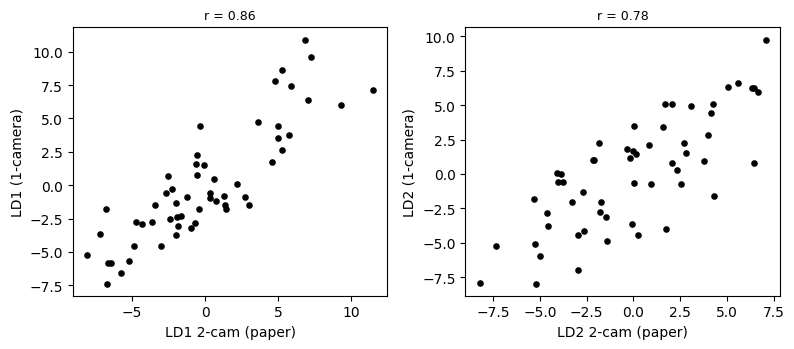

In [4]:
#%%
""" 2. IS IT THE PAPER'S LD1? mouse means, 1-camera vs 2-camera embedding (same sessions) """
lds = ['LD1', 'LD2', 'LD3', 'LD4']
mm = (sc.groupby('mouse_name')[lds].mean()
        .join(TWO.groupby('mouse_name')[['LD1', 'LD2', 'LD3']].mean(), rsuffix=' 2-cam', how='inner'))
print(f'{len(mm)} mice in both')
display(mm.corr().loc[lds, ['LD1 2-cam', 'LD2 2-cam', 'LD3 2-cam']].round(2))

fig, ax = plt.subplots(1, 2, figsize=(8, 3.6))
for a, (x, y) in zip(ax, [('LD1 2-cam', 'LD1'), ('LD2 2-cam', 'LD2')]):
    a.scatter(mm[x], mm[y], s=14, color='k')
    a.set_xlabel(f'{x} (paper)'); a.set_ylabel(f'{y} (1-camera)')
    a.set_title(f'r = {np.corrcoef(mm[x], mm[y])[0, 1]:.2f}', fontsize=9)
plt.tight_layout(); plt.show()

The 2-camera LD3 (paw **laterality**, `lda3-is-paw-laterality`) has no 1-camera counterpart; it
spreads weakly over LD3 / LD4. That is expected: the right paw is not in these features.

In [5]:
#%%
""" LAB SHARE PER LD (lab_controls.section_ldvar on this embedding) """
lab = p.use_in_lab_controls(p.as_lab_controls_lda(sc), p.OUT / 'lab_controls')
ldvar = lab.section_ldvar(rng, n_perm=2000)

lab share of all between-mouse variance: 0.283, shuffled labs 0.175 (95%: 0.200), p = 0.0005

=== lab share of between-mouse variance per LD (58 mice, 11 labs, 57 LDs) ===
 LD  share_between_mouse_var  eta2_lab  null_mean  null_95     p     q
  1                    0.122     0.538      0.175    0.301 0.000 0.009
  2                    0.106     0.214      0.174    0.298 0.268 0.964
  3                    0.095     0.455      0.174    0.301 0.000 0.009
  4                    0.076     0.493      0.175    0.308 0.000 0.009
  5                    0.063     0.124      0.179    0.311 0.755 0.996
  6                    0.055     0.289      0.176    0.303 0.070 0.655
  7                    0.046     0.171      0.176    0.301 0.472 0.964
  8                    0.041     0.159      0.176    0.305 0.555 0.964
  9                    0.036     0.158      0.174    0.301 0.551 0.964
 10                    0.032     0.281      0.175    0.298 0.074 0.655
 11                    0.027     0.245      0.1


=== mixed model: lab share of each LD's inter-individual variance, s2_lab / (s2_lab + s2_mouse) ===
 LD  mixed_share  mixed_share_clipped  mixed_ci_lo  mixed_ci_hi  mixed_null_mean  mixed_null_95  mixed_p  mixed_q  mixed_share_reml  mouse_over_session
  1        0.480                0.480        0.081        0.595           -0.010          0.176    0.000    0.009             0.422               6.162
  2        0.022                0.022        0.000        0.261           -0.040          0.135    0.240    0.999             0.023              10.509
  3        0.449                0.449        0.116        0.589            0.002          0.189    0.000    0.009             0.377               6.592
  4        0.409                0.409        0.032        0.599           -0.004          0.183    0.000    0.009             0.390               5.232
  5       -0.101                0.000        0.000        0.000           -0.028          0.155    0.751    0.999             0.000        

In [6]:
#%%
""" 3a. THE PAPER'S LD1 BATTERY on the 1-camera LD1 (trial-level and engagement sections) """
battery = pd.DataFrame(lab.section_trial(rng) + lab.section_engage(rng))


=== trial-level correlates (session_trial_meta_19-08-2026, 250 sessions) ===
               correlate  rho_session  p_session  n_mice    rho     p  rho_lab  p_lab  rho_within  p_within  eta2_lab_y
  Accuracy (easy trials)        0.131      0.038      57  0.117 0.385    0.134  0.429       0.056     0.377       0.234
             Choice bias       -0.191      0.002      57 -0.135 0.318   -0.066  0.713      -0.173     0.006       0.271
        Block bias shift       -0.033      0.608      57  0.049 0.716    0.283  0.075      -0.026     0.683       0.122
     Reaction time (log)       -0.420      0.000      57 -0.552 0.000   -0.581  0.000      -0.264     0.000       0.149
  Trial elongation (log)        0.205      0.001      57  0.319 0.015    0.344  0.032       0.236     0.000       0.162
Training time (log days)          NaN        NaN      56 -0.327 0.014   -0.285  0.033         NaN       NaN       0.336


engage: 253 sessions; check switches vs LD1 session-level r = -0.3199 (fig_engagement: -0.3418, n = 244)



=== engagement correlates ===
                          correlate  rho_session  p_session  n_mice    rho     p  rho_lab  p_lab  rho_within  p_within  eta2_lab_y
               State switches (K=2)       -0.320      0.000      58 -0.356 0.006   -0.449  0.002       0.031     0.622       0.156
     State switches | easy accuracy       -0.250      0.000      58 -0.269 0.042   -0.365  0.016       0.123     0.052       0.288
                    P(stay engaged)        0.301      0.000      58  0.345 0.008    0.414  0.007      -0.011     0.860       0.144
                 P(stay disengaged)        0.106      0.102      58  0.133 0.321    0.353  0.028      -0.051     0.434       0.212
Short disengaged bouts (<=2 trials)       -0.308      0.000      58 -0.340 0.009   -0.476  0.001       0.047     0.456       0.143
              Posterior uncertainty       -0.308      0.000      58 -0.287 0.029   -0.325  0.034      -0.049     0.436       0.111
        Engaged log posterior ratio        0.229    

In [7]:
#%%
""" 3b. WHEEL / PAW VIGOR (vigor/lda tables): mouse means, raw and lab-centred, LD1 and LD2.
gate = log(pre-quiescence speed / quiescence speed); per-epoch speeds are mouse-level in vigor_mouse_level.csv
(56 mice), whole-session metrics are per session. """
ses, tim, E = p.vigor_tables()
M = ses[['wheel_mean_speed', 'wheel_mean_speed_moving', 'wheel_frac_moving', 'wheel_bout_rate_per_min',
         'l_paw_mean_speed', 'l_paw_mean_speed_moving', 'l_paw_frac_moving', 'l_paw_band_0.5_8',
         'paw_hf_noise', 'native_hz']].join(tim[['dur_Pre-quiescence', 'dur_Quiescence', 'dur_Choice', 'dur_ITI']])
vig = pd.concat([p.mouse_corr(sc, M, cols=('LD1', 'LD2'), n_perm=2000),
                 p.mouse_corr(sc, E, cols=('LD1', 'LD2'), n_perm=2000)])
(vig.pivot(index='metric', columns='ld', values=['n_mice', 'r', 'r_lab', 'p_lab'])
    .sort_values(('r', 'LD1')).round(3))

n_mice            r         r_lab         p_lab       
ld                            LD1   LD2    LD1    LD2    LD1    LD2    LD1    LD2
metric                                                                           
wheel_gate                   56.0  56.0 -0.637 -0.003 -0.601  0.005  0.000  0.972
paw_gate                     56.0  56.0 -0.614  0.199 -0.571  0.281  0.000  0.028
wheel_speed_Pre-quiescence   56.0  56.0 -0.423  0.202 -0.493  0.178  0.001  0.197
wheel_mean_speed_moving      58.0  58.0 -0.391  0.109 -0.468 -0.016  0.002  0.912
dur_Quiescence               58.0  58.0 -0.362 -0.282 -0.351 -0.373  0.024  0.003
l_paw_mean_speed_moving      58.0  58.0 -0.325  0.079 -0.372  0.141  0.010  0.363
paw_speed_Pre-quiescence     56.0  56.0 -0.284  0.181 -0.286  0.266  0.033  0.085
dur_ITI                      58.0  58.0 -0.244 -0.204 -0.165 -0.021  0.239  0.871
dur_Choice                   58.0  58.0 -0.164 -0.032 -0.259 -0.086  0.107  0.610
l_paw_mean_speed             58.0  58.0 -0.132  0.087 -0.168  0.145  0.279  0.369
wheel_mean_speed             58.0  58.0 -0.124  0.211 -0.226  0.175  0.135  0.232
l_paw_band_0.5_8             58.0  58.0 -0.092 -0.006 -0.172  0.077  0.246  0.642
wheel_speed_ITI              56.0  56.0 -0.011  0.362 -0.298  0.344  0.039  0.027
native_hz                    58.0  58.0 -0.008  0.094 -0.064 -0.067  0.637  0.291
paw_speed_ITI                56.0  56.0  0.018  0.355 -0.046  0.478  0.760  0.006
l_paw_frac_moving            58.0  58.0  0.037  0.138  0.074  0.170  0.644  0.281
paw_hf_noise                 58.0  58.0  0.178  0.083  0.040  0.105  0.803  0.583
wheel_frac_moving            58.0  58.0  0.213  0.189  0.162  0.245  0.279  0.116
wheel_bout_rate_per_min      58.0  58.0  0.262  0.164  0.288  0.257  0.051  0.087
wheel_speed_Choice           56.0  56.0  0.264  0.179  0.316  0.266  0.052  0.085
paw_speed_Choice             56.0  56.0  0.321  0.157  0.432  0.253  0.009  0.094
dur_Pre-quiescence           58.0  58.0  0.371  0.294  0.308  0.309  0.068  0.017
wheel_speed_Quiescence       56.0  56.0  0.539  0.176  0.574  0.143  0.000  0.303
paw_speed_Quiescence         56.0  56.0  0.558 -0.071  0.594 -0.126  0.001  0.327

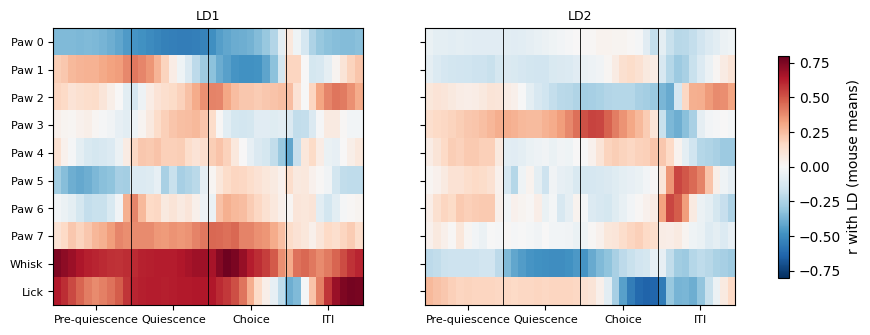

,Paw 0,Paw 1,Paw 2,Paw 3,Paw 4,Paw 5,Paw 6,Paw 7,Whisk,Lick
Pre-quiescence,-0.38,0.28,0.09,-0.00,-0.04,-0.34,-0.07,0.25,0.64,0.49
Quiescence,-0.53,0.10,0.14,0.16,0.18,-0.16,0.13,0.37,0.64,0.63
Choice,-0.35,-0.40,0.27,-0.07,-0.01,0.10,0.16,0.39,0.62,0.30
ITI,-0.23,0.05,0.27,-0.05,-0.03,-0.04,0.00,0.13,0.46,0.34


In [8]:
#%%
""" 3c. LOADINGS: per (bin, feature), r of the mouse-mean occupancy with the mouse-mean LD (structure
coefficients; reference paw state restored). Paw states are vigor-numbered: 0 = stillest. """
vig.to_csv(p.OUT / 'ld1_vigor_correlates.csv', index=False)      # for 2_nm_lda
battery.to_csv(p.OUT / 'ld1_battery.csv', index=False)
EPOCHS = ['Pre-quiescence', 'Quiescence', 'Choice', 'ITI']
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for a, ld in zip(ax, ['LD1', 'LD2']):
    L = p.loading_profile(sc, X, ld)
    im = a.imshow(L.T, aspect='auto', cmap='RdBu_r', vmin=-.8, vmax=.8)
    for e in (10, 20, 30):
        a.axvline(e - .5, color='k', lw=.6)
    a.set_xticks([5, 15, 25, 35]); a.set_xticklabels(EPOCHS, fontsize=8)
    a.set_yticks(range(L.shape[1])); a.set_yticklabels(L.columns, fontsize=8)
    a.set_title(ld, fontsize=9)
fig.colorbar(im, ax=ax, label='r with LD (mouse means)', shrink=.8)
plt.show()
p.loading_profile(sc, X, 'LD1').groupby(np.repeat(EPOCHS, 10), sort=False).mean().round(2)

## Reading

- **Mouse identity survives losing the right paw**: LOSO 0.86 [0.81, 0.91] for 58 mice (2-camera ≈ 0.85).
- **LD1 is the paper's LD1** (r ≈ 0.86, mouse means); LD2 ≈ 2-camera LD2 (≈ 0.78), with some 1–2 mixing.
- **What high LD1 is** (sign aligned to the 2-camera LD1):
  - *syllables*: whisking and licking in every epoch, little of the stillest paw state;
  - *movement gating*: **more** wheel and paw movement **during quiescence**, less before it, so the
    pre-quiescence / quiescence gate is weak (r ≈ −0.6, unchanged by lab-centring); whole-session amplitude
    (`l_paw_band_0.5_8`, `wheel_mean_speed`) is flat;
  - *task*: faster RT (r ≈ −0.55), fewer GLM-HMM state switches / longer engaged bouts (≈ −0.36 / +0.35,
    stronger within lab), shorter training; accuracy and block bias are unrelated;
  - all of these are **between-mouse** (within-mouse r ≈ 0), except RT and elongation.
- **Lab**: about half of LD1's between-mouse variance is between labs (η² 0.54, mixed-model share 0.48),
  as for the 2-camera LD1 (`lda1-lab-variance`). The correlates above mostly hold *within* lab.

One axis, read two ways: a still, sharply-gated, slow, switchy end against an aroused (whisking, licking,
fidgeting through the hold), fast, steadily engaged end.